# Part 3 — Mixture of LoRA experts (MixLoRA) on UberText-GEC
Base model: Qwen3-1.7B (dense, SwiGLU FFN). Task: Ukrainian grammatical error correction.
MixLoRA (E=8, top-2) with three balancing variants vs three plain-LoRA baselines
(rank 16, rank matched to total trainable params, rank matched to active params per token).

## Setup & config

In [1]:
!pip install -q torch==2.11.0 --index-url https://download.pytorch.org/whl/cu128
!pip install -q transformers==5.16.1 sacrebleu nltk rouge-score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 6.5 MB/s eta 0:00:00


In [2]:
import os, gc, json, math, time, random, hashlib, inspect
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer
from huggingface_hub import hf_hub_download

MODEL_ID = "Qwen/Qwen3-1.7B"
DATASET_ID = "lang-uk/UberText-GEC"
WORK = "/kaggle/working/"
RUN_DIR = f"{WORK}/part3_runs"
DATA_PATH = f"{WORK}/part3_data.pt"
DEVICE = "cuda"
os.makedirs(RUN_DIR, exist_ok=True)


PREV_DIR = "/kaggle/input/part3-runs"
RUN_NOW = None
RUN_SMOKE = False

import shutil
KEEP = {"part3_data.pt", "runs.json", "predictions.json", "reference_points.json"}
restored = []
for root, _, files in os.walk("/kaggle/input"):
    for fn in files:
        if not (fn in KEEP or fn.startswith(("mixlora_", "lora_"))):
            continue
        dst = DATA_PATH if fn == os.path.basename(DATA_PATH) else os.path.join(RUN_DIR, fn)
        if not os.path.exists(dst):
            shutil.copy(os.path.join(root, fn), dst)
            restored.append(fn)
print("restored:", sorted(restored) or "nothing (no previous session attached)")

CFG3 = dict(
    model_id=MODEL_ID,
    dataset_id=DATASET_ID,
    transformers=transformers.__version__,
    torch=torch.__version__,
    seed=42,
    n_experts=8, top_k=2,
    expert_rank=8,            
    attn_rank=8,              
    lora_alpha_ratio=2.0,     
    router_init_std=0.02,     
    baseline_rank=16,
    max_src_tokens=192, max_tgt_tokens=224,
    split_mod=100, val_buckets=3,          #
    n_train=20000, n_val=500, n_test=1000,
    max_identical_frac=0.2,  
    micro_bs=4, grad_accum=4, n_steps=1000,   
    lr_lora=2e-4, lr_router=1e-3,
    warmup_steps=50, min_lr_ratio=0.1, weight_decay=0.0, grad_clip=1.0,
    adam_betas=(0.9, 0.999),
    grad_checkpointing=True,
    eval_every=200, eval_bs=16,
    aux_coef=1e-2,
    bias_update_rate=1e-4,    
)

with open(f"{WORK}/config_part3.json", "w") as f:
    json.dump(CFG3, f, indent=2)


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(CFG3["seed"])
print(json.dumps(CFG3, indent=2))

restored: ['lora_r44_total_match.json', 'lora_r44_total_match__adapters.pt', 'mixlora_aux_1e-2.json', 'mixlora_aux_1e-2__adapters.pt', 'mixlora_loss_free.json', 'mixlora_loss_free__adapters.pt', 'mixlora_no_balance.json', 'mixlora_no_balance__adapters.pt', 'part3_data.pt', 'predictions.json', 'reference_points.json', 'runs.json']
{
  "model_id": "Qwen/Qwen3-1.7B",
  "dataset_id": "lang-uk/UberText-GEC",
  "transformers": "5.16.1",
  "torch": "2.11.0+cu128",
  "seed": 42,
  "n_experts": 8,
  "top_k": 2,
  "expert_rank": 8,
  "attn_rank": 8,
  "lora_alpha_ratio": 2.0,
  "router_init_std": 0.02,
  "baseline_rank": 16,
  "max_src_tokens": 192,
  "max_tgt_tokens": 224,
  "split_mod": 100,
  "val_buckets": 3,
  "n_train": 20000,
  "n_val": 500,
  "n_test": 1000,
  "max_identical_frac": 0.2,
  "micro_bs": 4,
  "grad_accum": 4,
  "n_steps": 1000,
  "lr_lora": 0.0002,
  "lr_router": 0.001,
  "warmup_steps": 50,
  "min_lr_ratio": 0.1,
  "weight_decay": 0.0,
  "grad_clip": 1.0,
  "adam_betas": [


## Model loading + model card

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.padding_side = "right"
assert tokenizer.pad_token_id is not None


def load_base_model():
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float16, device_map=DEVICE)
    model.config.use_cache = False
    return model


model = load_base_model()
cfg = model.config
L = cfg.num_hidden_layers
H, I = cfg.hidden_size, cfg.intermediate_size
Q_DIM = cfg.num_attention_heads * cfg.head_dim
KV_DIM = cfg.num_key_value_heads * cfg.head_dim

for key in ["num_hidden_layers", "hidden_size", "intermediate_size", "num_attention_heads",
            "num_key_value_heads", "head_dim", "hidden_act", "vocab_size", "tie_word_embeddings"]:
    print(f"{key:22s} {getattr(cfg, key)}")

n_total = sum(p.numel() for p in model.parameters())
print(f"\ntotal params: {n_total/1e9:.3f}B")

mlp0 = model.model.layers[0].mlp
attn0 = model.model.layers[0].self_attn
print("\nMLP class:", type(mlp0))
print(inspect.getsource(type(mlp0).forward))
for name in ["gate_proj", "up_proj", "down_proj"]:
    print(f"mlp.{name}: {tuple(getattr(mlp0, name).weight.shape)}")
for name in ["q_proj", "k_proj", "v_proj", "o_proj"]:
    print(f"self_attn.{name}: {tuple(getattr(attn0, name).weight.shape)}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

num_hidden_layers      28
hidden_size            2048
intermediate_size      6144
num_attention_heads    16
num_key_value_heads    8
head_dim               128
hidden_act             silu
vocab_size             151936
tie_word_embeddings    True

total params: 1.721B

MLP class: <class 'transformers.models.qwen3.modeling_qwen3.Qwen3MLP'>
    def forward(self, x):
        down_proj = self.down_proj(self.act_fn(self.gate_proj(x)) * self.up_proj(x))
        return down_proj

mlp.gate_proj: (6144, 2048)
mlp.up_proj: (6144, 2048)
mlp.down_proj: (2048, 6144)
self_attn.q_proj: (2048, 2048)
self_attn.k_proj: (1024, 2048)
self_attn.v_proj: (1024, 2048)
self_attn.o_proj: (2048, 2048)


## Trainable-parameter budget and matched LoRA ranks
Plain LoRA of rank r on a (d_in -> d_out) linear adds r * (d_in + d_out) parameters.
MixLoRA per layer = E experts x LoRA on (gate, up, down) + router (H x E) + LoRA on (q, k, v, o).
Active per token = the same with k experts instead of E.

In [4]:
ATTN_SHAPES = [(H, Q_DIM), (H, KV_DIM), (H, KV_DIM), (Q_DIM, H)]   
MLP_SHAPES = [(H, I), (H, I), (I, H)]                              


def lora_params(shapes, r):
    return sum(r * (d_in + d_out) for d_in, d_out in shapes)


def plain_lora_total(r):
    return L * lora_params(ATTN_SHAPES + MLP_SHAPES, r)


def mixlora_params(n_experts_counted):
    E, re, ra = CFG3["n_experts"], CFG3["expert_rank"], CFG3["attn_rank"]
    per_layer = n_experts_counted * lora_params(MLP_SHAPES, re) + H * E + lora_params(ATTN_SHAPES, ra)
    return L * per_layer


MIX_TOTAL = mixlora_params(CFG3["n_experts"])
MIX_ACTIVE = mixlora_params(CFG3["top_k"])
per_rank = plain_lora_total(1)
RANK_TOTAL_MATCH = round(MIX_TOTAL / per_rank)
RANK_ACTIVE_MATCH = round(MIX_ACTIVE / per_rank)

budget = pd.DataFrame([
    dict(config=f"MixLoRA E={CFG3['n_experts']} top-{CFG3['top_k']} (total)", params=MIX_TOTAL),
    dict(config=f"MixLoRA E={CFG3['n_experts']} top-{CFG3['top_k']} (active per token)", params=MIX_ACTIVE),
    dict(config=f"LoRA r={CFG3['baseline_rank']}", params=plain_lora_total(CFG3["baseline_rank"])),
    dict(config=f"LoRA r={RANK_TOTAL_MATCH} (matched to MixLoRA total)", params=plain_lora_total(RANK_TOTAL_MATCH)),
    dict(config=f"LoRA r={RANK_ACTIVE_MATCH} (matched to MixLoRA active)", params=plain_lora_total(RANK_ACTIVE_MATCH)),
])
budget["params_M"] = budget["params"] / 1e6
print(budget.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
CFG3.update(rank_total_match=RANK_TOTAL_MATCH, rank_active_match=RANK_ACTIVE_MATCH)

                               config   params  params_M
            MixLoRA E=8 top-2 (total) 47710208     47.71
 MixLoRA E=8 top-2 (active per token) 14680064     14.68
                            LoRA r=16 17432576     17.43
 LoRA r=44 (matched to MixLoRA total) 47939584     47.94
LoRA r=13 (matched to MixLoRA active) 14163968     14.16


## Data: UberText-GEC train / val, human-annotated test
UberText-GEC is Ukrainian Telegram posts corrected automatically by GPT-4o-mini (silver data),
one split, no document ids. `uber_uk_annotations.csv` holds 1,500 human-checked pairs: the
non-rejected ones are the test set, and every test text is removed from train / val.
Train / val are split by md5 of the source text, so duplicates always land in the same split.

In [5]:
PROMPT = ("Виправ граматичні, орфографічні та пунктуаційні помилки в тексті. "
          "Якщо помилок немає, поверни текст без змін.\n\nТекст: {src}")
IM_END_ID = tokenizer.convert_tokens_to_ids("<|im_end|>")


def prompt_ids(src: str):
    text = tokenizer.apply_chat_template([{"role": "user", "content": PROMPT.format(src=src)}],
                                         tokenize=False, add_generation_prompt=True, enable_thinking=False)
    return tokenizer(text, add_special_tokens=False)["input_ids"]


def build_example(src: str, tgt: str):
    """input_ids = prompt + target + <|im_end|>; loss only on target and <|im_end|>."""
    p = prompt_ids(src)
    t = tokenizer(tgt, add_special_tokens=False)["input_ids"] + [IM_END_ID]
    return dict(input_ids=p + t, labels=[-100] * len(p) + t)


def split_of(text: str) -> str:
    b = int(hashlib.md5(text.encode("utf-8")).hexdigest(), 16) % CFG3["split_mod"]
    return "val" if b < CFG3["val_buckets"] else "train"


def n_tok(texts):
    return [len(x) for x in tokenizer(list(texts), add_special_tokens=False)["input_ids"]]


def build_data():
    main = pd.read_csv(hf_hub_download(DATASET_ID, "uber_text_gec.csv", repo_type="dataset"))
    ann = pd.read_csv(hf_hub_download(DATASET_ID, "uber_uk_annotations.csv", repo_type="dataset"))
    stats = dict(main_rows=len(main), ann_rows=len(ann))
    print("main columns:", list(main.columns), "| annotation columns:", list(ann.columns))
    if "language" in main.columns:
        print("language values:", main["language"].value_counts().head(5).to_dict())
        main = main[main["language"] == "uk"]

    def clean(df):
        df = df.dropna(subset=["text", "correction"])
        df = df[(df["text"].str.strip() != "") & (df["correction"].str.strip() != "")]
        return df.drop_duplicates(subset=["text"])

    main, ann = clean(main), clean(ann)

    # test: human-accepted pairs only
    rejected = ann["is_rejected"].astype(str).str.lower().isin(["true", "1", "yes"])
    test = ann[~rejected][["text", "correction"]]
    stats.update(ann_rejected=int(rejected.sum()), ann_accepted=len(test))

    # train / val: everything else, never a test text
    main = main[~main["text"].isin(set(ann["text"]))]
    main = main.assign(split=main["text"].map(split_of))

    out = {}
    rng = np.random.default_rng(CFG3["seed"])
    for name, df, n in [("train", main[main.split == "train"], CFG3["n_train"]),
                        ("val", main[main.split == "val"], CFG3["n_val"]),
                        ("test", test, CFG3["n_test"])]:
        df = df.sample(frac=1.0, random_state=CFG3["seed"]).head(n * 4)   # shuffle
        df = df.assign(src_tok=n_tok(df["text"]), tgt_tok=n_tok(df["correction"]))
        df = df[(df.src_tok <= CFG3["max_src_tokens"]) & (df.tgt_tok <= CFG3["max_tgt_tokens"])]
        identical = df["text"] == df["correction"]
        stats[f"{name}_identical_frac_raw"] = float(identical.mean())
        if name != "test":  
            n_ident = min(int(identical.sum()), int(CFG3["max_identical_frac"] * n))
            df = pd.concat([df[~identical].head(n - n_ident), df[identical].head(n_ident)])
            df = df.sample(frac=1.0, random_state=int(rng.integers(1 << 31)))
        df = df.head(n)
        assert len(df) > 0, f"empty split {name}"
        out[name] = dict(src=df["text"].tolist(), tgt=df["correction"].tolist(),
                         src_tok=df["src_tok"].tolist(), tgt_tok=df["tgt_tok"].tolist())
        stats[f"{name}_n"] = len(df)
        stats[f"{name}_identical_frac"] = float((df["text"] == df["correction"]).mean())

    assert not (set(out["train"]["src"]) & set(out["test"]["src"]))
    assert not (set(out["train"]["src"]) & set(out["val"]["src"]))
    out["meta"] = stats
    return out


if os.path.exists(DATA_PATH):
    DATA3 = torch.load(DATA_PATH, weights_only=False)
else:
    DATA3 = build_data()
    torch.save(DATA3, DATA_PATH)

print(json.dumps(DATA3["meta"], indent=2))
for k in ["train", "val", "test"]:
    s, t = np.array(DATA3[k]["src_tok"]), np.array(DATA3[k]["tgt_tok"])
    print(f"{k:5s} n={len(s):6d}  src tokens median={np.median(s):.0f} p95={np.percentile(s, 95):.0f}  "
          f"tgt tokens median={np.median(t):.0f}")

{
  "main_rows": 157448,
  "ann_rows": 1500,
  "ann_rejected": 35,
  "ann_accepted": 1465,
  "train_identical_frac_raw": 0.0,
  "train_n": 20000,
  "train_identical_frac": 0.0,
  "val_identical_frac_raw": 0.0,
  "val_n": 500,
  "val_identical_frac": 0.0,
  "test_identical_frac_raw": 0.0,
  "test_n": 1000,
  "test_identical_frac": 0.0
}
train n= 20000  src tokens median=95 p95=178  tgt tokens median=97
val   n=   500  src tokens median=95 p95=177  tgt tokens median=98
test  n=  1000  src tokens median=94 p95=175  tgt tokens median=95


### Check the prompt format and the loss mask

In [6]:
ex = build_example(DATA3["train"]["src"][0], DATA3["train"]["tgt"][0])
first_label = next(i for i, x in enumerate(ex["labels"]) if x != -100)
print(repr(tokenizer.decode(ex["input_ids"][:first_label])))
print("--- loss is computed on:")
print(repr(tokenizer.decode(ex["input_ids"][first_label:])))
assert ex["input_ids"][-1] == IM_END_ID and ex["labels"][-1] == IM_END_ID
assert "<think>" in tokenizer.decode(ex["input_ids"][:first_label]), "expected the empty think block (enable_thinking=False)"

"<|im_start|>user\nВиправ граматичні, орфографічні та пунктуаційні помилки в тексті. Якщо помилок немає, поверни текст без змін.\n\nТекст: 🏃🏼\u200d♂️ Під час карантину багато хто займається спортом вдома. Тренуватися потрібно, але в таких умовах при неправильному підході можна зашкодити своєму здоров'ю. Розповідаємопро найпоширеніші помилки під час занять спортом вдома<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
--- loss is computed on:
"🏃🏼\u200d♂️ Під час карантину багато людей займаються спортом вдома. Тренуватися потрібно, але в таких умовах, при неправильному підході, можна зашкодити своєму здоров'ю. Розповімо про найпоширеніші помилки під час занять спортом вдома.<|im_end|>"


### Pre-tokenize every split once

In [7]:
TOK3 = {k: [build_example(s, t) for s, t in zip(DATA3[k]["src"], DATA3[k]["tgt"])] for k in ["train", "val", "test"]}
for k, exs in TOK3.items():
    lens = np.array([len(e["input_ids"]) for e in exs])
    print(f"{k:5s} n={len(exs)}  sequence length median={np.median(lens):.0f} max={lens.max()}")


def collate(exs):
    T = max(len(e["input_ids"]) for e in exs)
    ids = torch.full((len(exs), T), tokenizer.pad_token_id, dtype=torch.long)
    labels = torch.full((len(exs), T), -100, dtype=torch.long)
    att = torch.zeros((len(exs), T), dtype=torch.long)
    for i, e in enumerate(exs):
        n = len(e["input_ids"])
        ids[i, :n] = torch.tensor(e["input_ids"])
        labels[i, :n] = torch.tensor(e["labels"])
        att[i, :n] = 1
    return ids.to(DEVICE), att.to(DEVICE), labels.to(DEVICE)


def answer_loss(model, ids, att, labels):
    hidden = model.model(input_ids=ids, attention_mask=att, use_cache=False).last_hidden_state
    tgt = labels[:, 1:]
    sel = tgt != -100
    logits = model.lm_head(hidden[:, :-1][sel]).float()
    return F.cross_entropy(logits, tgt[sel]), int(sel.sum())

train n=20000  sequence length median=265 max=488
val   n=500  sequence length median=265 max=474
test  n=1000  sequence length median=261 max=480


## Adapter modules
**`LoRALinear`**: frozen base linear + `B @ A * (alpha / r)`, A Kaiming-uniform, B zeros, both fp32.

**`MixLoRAFFN`** replaces the whole Qwen3 MLP, `y = W_down(SiLU(W_gate x) * W_up x)`:
- E experts, each a LoRA on gate, up and down; all experts share the frozen W_gate, W_up, W_down
- fp32 softmax router, top-k, renormalized gates; the optional per-expert bias (Part 2) changes only
  *which* experts are selected, never the gate values
- `W_gate x` and `W_up x` are computed once per token; each expert only adds its LoRA delta
- W_down is linear, so `sum_e g_e W_down h_e = W_down(sum_e g_e h_e)`: the big down projection runs once
  on the gate-weighted mix; only the LoRA down deltas are per expert

At initialization every B is zero, so every expert equals the base FFN and the gates sum to 1:
the patched model must reproduce the base model exactly (tested below). For the same reason the router
gets no gradient at step 0 (all experts give the same output); it starts learning once the B's diverge.

In [8]:
class RouterRecorder:
    def __init__(self, n_layers: int):
        self.n_layers = n_layers
        self.recording = False
        self.mask = None
        self.records = [None] * n_layers

    def start(self, mask=None):
        self.records = [None] * self.n_layers
        self.mask = mask
        self.recording = True

    def stop(self):
        self.recording = False
        assert all(r is not None for r in self.records), "a router did not record"
        recs, self.records = self.records, [None] * self.n_layers
        if self.mask is not None:
            recs = [(lg[self.mask], pr[self.mask], ix[self.mask]) for lg, pr, ix in recs]
        return recs

    def record(self, layer_idx, logits, probs, idx):
        if not self.recording:
            return
        assert self.records[layer_idx] is None, f"layer {layer_idx} recorded twice in one forward"
        self.records[layer_idx] = (logits, probs, idx)


def lora_delta(x, A, B, scale):
    return F.linear(F.linear(x.to(A.dtype), A), B) * scale


def kaiming_(t):
    nn.init.kaiming_uniform_(t, a=math.sqrt(5))
    return t


class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, r: int):
        super().__init__()
        self.base = base
        self.scale = CFG3["lora_alpha_ratio"]          # alpha / r
        dev = base.weight.device
        self.A = nn.Parameter(kaiming_(torch.empty(r, base.in_features, device=dev)))
        self.B = nn.Parameter(torch.zeros(base.out_features, r, device=dev))

    def forward(self, x):
        return self.base(x) + lora_delta(x, self.A, self.B, self.scale).to(x.dtype)


class MixLoRAFFN(nn.Module):
    def __init__(self, mlp, layer_idx: int, recorder: RouterRecorder):
        super().__init__()
        self.gate_proj, self.up_proj, self.down_proj, self.act_fn = mlp.gate_proj, mlp.up_proj, mlp.down_proj, mlp.act_fn
        self.layer_idx, self.recorder = layer_idx, recorder
        self.E, self.top_k, r = CFG3["n_experts"], CFG3["top_k"], CFG3["expert_rank"]
        self.hidden, self.inter = mlp.gate_proj.in_features, mlp.gate_proj.out_features
        self.scale = CFG3["lora_alpha_ratio"]
        dev = mlp.gate_proj.weight.device

        def stack_A(d_in):
            return nn.Parameter(torch.stack([kaiming_(torch.empty(r, d_in, device=dev)) for _ in range(self.E)]))

        def stack_B(d_out):
            return nn.Parameter(torch.zeros(self.E, d_out, r, device=dev))

        self.A_gate, self.B_gate = stack_A(self.hidden), stack_B(self.inter)
        self.A_up, self.B_up = stack_A(self.hidden), stack_B(self.inter)
        self.A_down, self.B_down = stack_A(self.inter), stack_B(self.hidden)
        self.router = nn.Parameter(torch.randn(self.E, self.hidden, device=dev) * CFG3["router_init_std"])
        self.register_buffer("expert_bias", torch.zeros(self.E, dtype=torch.float32, device=dev), persistent=False)
        self.use_bias = False

    def route(self, xf):
        with torch.autocast(device_type=xf.device.type, enabled=False):
            logits = F.linear(xf.float(), self.router)
            probs = logits.softmax(dim=-1)
            scores = probs + self.expert_bias if self.use_bias else probs
            idx = scores.topk(self.top_k, dim=-1).indices
            gates = probs.gather(-1, idx)                     
            gates = gates / gates.sum(dim=-1, keepdim=True)
        return logits, probs, idx, gates

    def forward(self, x):
        shape = x.shape
        xf = x.reshape(-1, self.hidden)
        logits, probs, idx, gates = self.route(xf)
        self.recorder.record(self.layer_idx, logits, probs, idx)

        base_g, base_u = self.gate_proj(xf), self.up_proj(xf)       # shared frozen projections, once per token
        mixed = torch.zeros(xf.shape[0], self.inter, device=xf.device, dtype=torch.float32)
        lora_out = torch.zeros(xf.shape[0], self.hidden, device=xf.device, dtype=torch.float32)
        for e in range(self.E):
            tok, slot = torch.where(idx == e)
            if tok.numel() == 0:
                continue
            xe = xf[tok]
            w = gates[tok, slot].unsqueeze(-1)
            g = base_g[tok] + lora_delta(xe, self.A_gate[e], self.B_gate[e], self.scale).to(base_g.dtype)
            u = base_u[tok] + lora_delta(xe, self.A_up[e], self.B_up[e], self.scale).to(base_u.dtype)
            h = self.act_fn(g) * u
            mixed = mixed.index_add(0, tok, h.float() * w)
            lora_out = lora_out.index_add(0, tok, lora_delta(h, self.A_down[e], self.B_down[e], self.scale).float() * w)
        y = self.down_proj(mixed.to(x.dtype)) + lora_out.to(x.dtype)  
        return y.reshape(shape)


ATTN_NAMES = ["q_proj", "k_proj", "v_proj", "o_proj"]
MLP_NAMES = ["gate_proj", "up_proj", "down_proj"]


def patch_model(model, spec):
    for p in model.parameters():
        p.requires_grad_(False)
    recorder, routers = RouterRecorder(L), []
    for i, layer in enumerate(model.model.layers):
        r_attn = spec["rank"] if spec["kind"] == "lora" else CFG3["attn_rank"]
        for nm in ATTN_NAMES:
            setattr(layer.self_attn, nm, LoRALinear(getattr(layer.self_attn, nm), r_attn))
        if spec["kind"] == "lora":
            for nm in MLP_NAMES:
                setattr(layer.mlp, nm, LoRALinear(getattr(layer.mlp, nm), spec["rank"]))
        else:
            layer.mlp = MixLoRAFFN(layer.mlp, i, recorder)
            routers.append(layer.mlp)
    return recorder, routers


def n_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def expected_trainable(spec):
    return plain_lora_total(spec["rank"]) if spec["kind"] == "lora" else MIX_TOTAL

### Equivalence test: patched model at init == base model

In [9]:
test_batch = collate(TOK3["val"][:4])
real = test_batch[1].bool()
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    out_base = model(input_ids=test_batch[0], attention_mask=test_batch[1], labels=test_batch[2])
logits_base, loss_base = out_base.logits.float()[real], out_base.loss.item()
del out_base
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    loss_answer, _ = answer_loss(model, *test_batch)
print(f"answer_loss vs HF loss on the base model: {loss_answer.item():.5f} vs {loss_base:.5f}")
assert abs(loss_answer.item() - loss_base) < 1e-3, "answer_loss does not match the HF loss"

set_seed(CFG3["seed"])
recorder_eq, routers_eq = patch_model(model, dict(kind="mixlora"))
assert n_trainable(model) == MIX_TOTAL, (n_trainable(model), MIX_TOTAL)
recorder_eq.start(real.flatten())
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    out_mix = model(input_ids=test_batch[0], attention_mask=test_batch[1], labels=test_batch[2])
recs = recorder_eq.stop()

diff = (out_mix.logits.float()[real] - logits_base).abs().max().item()
print(f"MixLoRA at init: max |logit diff| on real tokens = {diff:.3e}, "
      f"loss base={loss_base:.4f} patched={out_mix.loss.item():.4f}")
print(f"trainable params: {n_trainable(model)/1e6:.2f}M (expected {MIX_TOTAL/1e6:.2f}M)")
print(f"router recorded {recs[0][2].shape[0]} tokens, attention-mask sum = {int(real.sum())}")
assert recs[0][2].shape[0] == int(real.sum()), "padding leaked into routing stats"
assert abs(out_mix.loss.item() - loss_base) < 1e-2 and diff < 0.5   
r0 = routers_eq[0]
x0 = torch.randn(16, H, device=DEVICE, dtype=torch.float16)
r0.use_bias = True
r0.expert_bias[0] = 10.0
with torch.no_grad():
    _, probs0, idx0, gates0 = r0.route(x0)
assert (idx0 == 0).any(-1).all(), "bias did not force expert 0 into top-k"
expected = probs0.gather(-1, idx0)
assert torch.allclose(gates0, expected / expected.sum(-1, keepdim=True)), "bias leaked into gate values"
r0.expert_bias.zero_()
r0.use_bias = False
print("bias test OK")

del model, out_mix, logits_base, recs, routers_eq, recorder_eq, r0
gc.collect()
torch.cuda.empty_cache()

answer_loss vs HF loss on the base model: 0.54828 vs 0.54828
MixLoRA at init: max |logit diff| on real tokens = 0.000e+00, loss base=0.5483 patched=0.5483
trainable params: 47.71M (expected 47.71M)
router recorded 1303 tokens, attention-mask sum = 1303
bias test OK


## Balancing (reused from Part 2) and routing metrics

In [10]:
E, K = CFG3["n_experts"], CFG3["top_k"]


def balance_loss(recs):
    aux_terms, counts = [], []
    for logits, probs, idx in recs:
        c = torch.bincount(idx.flatten(), minlength=E).float()
        f = c / (idx.shape[0] * K)          
        P = probs.mean(0)                   #
        aux_terms.append(E * (f * P).sum())
        counts.append(c)
    return torch.stack(aux_terms).mean(), torch.stack(counts).detach()


@torch.no_grad()
def update_expert_bias(routers, step_counts, rate):
    for l, r in enumerate(routers):
        c = step_counts[l].to(r.expert_bias.device).float()
        r.expert_bias += rate * torch.sign(c.mean() - c)


def maxvio(counts):
    counts = counts.double()
    mean = counts.mean(-1)
    return (counts.max(-1).values - mean) / mean


def load_entropy(counts):
    f = counts.double() / counts.double().sum(-1, keepdim=True)
    return -(f * f.clamp_min(1e-12).log()).sum(-1) / math.log(counts.shape[-1])


def random_router_floor(n_tokens, n_rep=20, seed=0):
    g = torch.Generator().manual_seed(seed)
    mv, ent = [], []
    for _ in range(n_rep):
        idx = torch.rand(n_tokens, E, generator=g).topk(K, dim=-1).indices
        c = torch.bincount(idx.flatten(), minlength=E)[None]
        mv.append(maxvio(c).item())
        ent.append(load_entropy(c).item())
    return dict(maxvio_mean=float(np.mean(mv)), maxvio_std=float(np.std(mv)),
                entropy_mean=float(np.mean(ent)), entropy_std=float(np.std(ent)))

## Evaluation: teacher-forced loss, routing stats, generation, task metrics
- GLEU: nltk `corpus_gleu` (Google GLEU, references only); BLEU: sacrebleu; ROUGE: rouge-score.
- rouge-score's default tokenizer drops every non-Latin character, which would score Ukrainian as empty
  strings, so a Unicode-aware tokenizer is passed explicitly.
- Copying the source unchanged already scores high on all three in GEC; it is reported as the floor.

In [11]:
import re
import sacrebleu
from nltk.translate.gleu_score import corpus_gleu
from rouge_score import rouge_scorer

WORD_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)


class UnicodeTokenizer:
    def tokenize(self, text):
        return WORD_RE.findall(text.lower())


ROUGE = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], tokenizer=UnicodeTokenizer())
assert ROUGE.score("Привіт, світе", "Привіт, світе")["rougeL"].fmeasure == 1.0


def task_metrics(hyps, refs):
    tok = UnicodeTokenizer().tokenize
    rouge = [ROUGE.score(r, h) for h, r in zip(hyps, refs)]
    return dict(
        bleu=sacrebleu.corpus_bleu(hyps, [refs]).score,
        gleu=corpus_gleu([[tok(r)] for r in refs], [tok(h) for h in hyps]) * 100,
        rouge1=float(np.mean([s["rouge1"].fmeasure for s in rouge])) * 100,
        rouge2=float(np.mean([s["rouge2"].fmeasure for s in rouge])) * 100,
        rougeL=float(np.mean([s["rougeL"].fmeasure for s in rouge])) * 100,
        exact_match=float(np.mean([h.strip() == r.strip() for h, r in zip(hyps, refs)])) * 100,
    )


@torch.no_grad()
def evaluate_tf(model, recorder, routers, exs, bs=None):
    bs = bs or CFG3["eval_bs"]
    was_training = model.training
    model.eval()
    counts = torch.zeros(L, E, dtype=torch.float64) if routers else None
    nll, n_tok_total = 0.0, 0
    for i in range(0, len(exs), bs):
        ids, att, labels = collate(exs[i:i + bs])
        if routers:
            recorder.start(att.flatten().bool())
        with torch.autocast("cuda", dtype=torch.float16):
            loss, n = answer_loss(model, ids, att, labels)
        if routers:
            for l, (_, _, idx) in enumerate(recorder.stop()):
                counts[l] += torch.bincount(idx.flatten(), minlength=E).double().cpu()
        nll += loss.item() * n
        n_tok_total += n
        del loss
    if was_training:
        model.train()
    res = dict(loss=nll / n_tok_total)
    if routers:
        res.update(counts=counts, maxvio=maxvio(counts), entropy=load_entropy(counts))
    return res


@torch.no_grad()
def generate_corrections(model, srcs, bs=None):
    bs = bs or CFG3["eval_bs"]
    model.eval()
    prompts = [prompt_ids(s) for s in srcs]
    order = np.argsort([-len(p) for p in prompts])
    outs = [None] * len(srcs)
    for i in range(0, len(order), bs):
        batch_idx = order[i:i + bs]
        T = max(len(prompts[j]) for j in batch_idx)
        ids = torch.full((len(batch_idx), T), tokenizer.pad_token_id, dtype=torch.long)
        att = torch.zeros((len(batch_idx), T), dtype=torch.long)
        for row, j in enumerate(batch_idx):
            p = prompts[j]
            ids[row, T - len(p):] = torch.tensor(p)
            att[row, T - len(p):] = 1
        with torch.autocast("cuda", dtype=torch.float16):
            gen = model.generate(input_ids=ids.to(DEVICE), attention_mask=att.to(DEVICE),
                                 max_new_tokens=CFG3["max_tgt_tokens"] + 8, do_sample=False,
                                 temperature=None, top_p=None, top_k=None,
                                 eos_token_id=IM_END_ID, pad_token_id=tokenizer.pad_token_id, use_cache=True)
        for row, j in enumerate(batch_idx):
            outs[j] = tokenizer.decode(gen[row, T:], skip_special_tokens=True).strip()
    return outs

### Reference points: copy-the-source floor and zero-shot base model

In [12]:
REF_PATH = f"{RUN_DIR}/reference_points.json"
test_src, test_ref = DATA3["test"]["src"], DATA3["test"]["tgt"]
if os.path.exists(REF_PATH):
    with open(REF_PATH) as f:
        REFERENCE = json.load(f)
else:
    REFERENCE = {"copy source": task_metrics(test_src, test_ref)}
    set_seed(CFG3["seed"])
    base_model = load_base_model()
    t0 = time.time()
    zs = generate_corrections(base_model, test_src)
    REFERENCE["zero-shot base"] = dict(task_metrics(zs, test_ref), gen_min=(time.time() - t0) / 60)
    REFERENCE["zero-shot examples"] = [dict(src=s, hyp=h, ref=r) for s, h, r in list(zip(test_src, zs, test_ref))[:5]]
    del base_model
    gc.collect()
    torch.cuda.empty_cache()
    with open(REF_PATH, "w") as f:
        json.dump(REFERENCE, f, indent=2, ensure_ascii=False)

for k in ["copy source", "zero-shot base"]:
    print(f"{k:16s}", {m: round(v, 2) for m, v in REFERENCE[k].items()})

FLOOR = random_router_floor(int(sum(len(e["input_ids"]) for e in TOK3["test"])))
print("random-router floor on the test tokens:", FLOOR)

copy source      {'bleu': 66.59, 'gleu': 69.98, 'rouge1': 83.31, 'rouge2': 71.63, 'rougeL': 81.61, 'exact_match': 0.0}
zero-shot base   {'bleu': 46.7, 'gleu': 48.36, 'rouge1': 72.51, 'rouge2': 62.27, 'rougeL': 70.51, 'exact_match': 0.2, 'gen_min': 12.47}
random-router floor on the test tokens: {'maxvio_mean': 0.004898253196470376, 'maxvio_std': 0.0008835008108289111, 'entropy_mean': 0.9999973496172361, 'entropy_std': 8.758964335245899e-07}


## Runs

In [13]:
RUNS = {
    "mixlora_no_balance": dict(kind="mixlora", aux=0.0, loss_free=False),
    "mixlora_aux_1e-2":   dict(kind="mixlora", aux=CFG3["aux_coef"], loss_free=False),
    "mixlora_loss_free":  dict(kind="mixlora", aux=0.0, loss_free=True),
    f"lora_r{CFG3['baseline_rank']}":            dict(kind="lora", rank=CFG3["baseline_rank"]),
    f"lora_r{RANK_TOTAL_MATCH}_total_match":    dict(kind="lora", rank=RANK_TOTAL_MATCH),
    f"lora_r{RANK_ACTIVE_MATCH}_active_match":  dict(kind="lora", rank=RANK_ACTIVE_MATCH),
}
with open(f"{RUN_DIR}/runs.json", "w") as f:
    json.dump(RUNS, f, indent=2)

## Pre-registered predictions (fill in BEFORE running the strategies)
`None` entries are skipped in the prediction-error table.

In [14]:
PREDICTIONS = {
    "mixlora_no_balance":  dict(gleu=None, val_loss=None, maxvio=None),
    "mixlora_aux_1e-2":    dict(gleu=None, val_loss=None, maxvio=None),
    "mixlora_loss_free":   dict(gleu=None, val_loss=None, maxvio=None),
    f"lora_r{CFG3['baseline_rank']}":           dict(gleu=None, val_loss=None),
    f"lora_r{RANK_TOTAL_MATCH}_total_match":   dict(gleu=None, val_loss=None),
    f"lora_r{RANK_ACTIVE_MATCH}_active_match": dict(gleu=None, val_loss=None),
}
pred_path = f"{RUN_DIR}/predictions.json"
registered_empty = False
if os.path.exists(pred_path):
    with open(pred_path) as f:
        registered_empty = all(v is None for p in json.load(f)["predictions"].values() for v in p.values())
if not os.path.exists(pred_path) or registered_empty:  
    with open(pred_path, "w") as f:
        json.dump(dict(timestamp=time.strftime("%Y-%m-%d %H:%M:%S"), predictions=PREDICTIONS), f, indent=2)

## Training
Same data order, step budget, seed and hyperparameters for every run. Base weights fp16 and frozen;
adapter weights fp32 (fp16 autocast matmuls, GradScaler). Routers get their own learning rate.

In [15]:
def make_lr_lambda(n_steps):
    w, m = CFG3["warmup_steps"], CFG3["min_lr_ratio"]

    def f(step):
        if step < w:
            return (step + 1) / w
        prog = (step - w) / max(1, n_steps - w)
        return m + (1 - m) * 0.5 * (1 + math.cos(math.pi * prog))
    return f


def summarize_routing(res):
    return dict(maxvio_per_layer=res["maxvio"].tolist(), maxvio_mean=res["maxvio"].mean().item(),
                maxvio_max=res["maxvio"].max().item(), entropy_per_layer=res["entropy"].tolist(),
                entropy_mean=res["entropy"].mean().item())


def train_run(name, spec, seed=None, n_steps=None, save=True):
    seed = seed if seed is not None else CFG3["seed"]
    n_steps = n_steps or CFG3["n_steps"]
    out_path = f"{RUN_DIR}/{name}.json"
    if save and os.path.exists(out_path):
        print(f"[{name}] already done, loading")
        with open(out_path) as f:
            return json.load(f)

    set_seed(seed)
    torch.cuda.reset_peak_memory_stats()
    model = load_base_model()
    recorder, routers = patch_model(model, spec)
    for r in routers:
        r.use_bias = spec.get("loss_free", False)
    assert n_trainable(model) == expected_trainable(spec), (n_trainable(model), expected_trainable(spec))

    router_params = [r.router for r in routers]
    router_ids = {id(p) for p in router_params}
    lora_params = [p for p in model.parameters() if p.requires_grad and id(p) not in router_ids]
    groups = [dict(params=lora_params, lr=CFG3["lr_lora"])]
    if router_params:
        groups.append(dict(params=router_params, lr=CFG3["lr_router"]))
    trainable = [p for g_ in groups for p in g_["params"]]
    opt = torch.optim.AdamW(groups, betas=CFG3["adam_betas"], weight_decay=CFG3["weight_decay"])
    sched = torch.optim.lr_scheduler.LambdaLR(opt, make_lr_lambda(n_steps))
    scaler = torch.amp.GradScaler("cuda")
    if CFG3["grad_checkpointing"]:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.train()

    train = TOK3["train"]
    mb, ga = CFG3["micro_bs"], CFG3["grad_accum"]
    n_needed = n_steps * mb * ga
    g = torch.Generator().manual_seed(seed)
    order = torch.cat([torch.randperm(len(train), generator=g) for _ in range(math.ceil(n_needed / len(train)))])

    hist = dict(step=[], lm_loss=[], aux=[], batch_maxvio_mean=[], batch_maxvio_max=[],
                batch_entropy_mean=[], bias_absmax=[], step_time=[], val=[])
    t_train, ptr = 0.0, 0
    for step in range(n_steps):
        torch.cuda.synchronize()
        t_step = time.time()
        step_counts = torch.zeros(L, E, device=DEVICE)
        lm_acc = aux_acc = 0.0
        for _ in range(ga):
            ids, att, labels = collate([train[j] for j in order[ptr:ptr + mb].tolist()])
            ptr += mb
            if routers:
                recorder.start(att.flatten().bool())
            with torch.autocast("cuda", dtype=torch.float16):
                lm_loss, _ = answer_loss(model, ids, att, labels)
            loss = lm_loss
            if routers:
                recs = recorder.stop()     
                aux, counts = balance_loss(recs)
                loss = loss + spec.get("aux", 0.0) * aux
                step_counts += counts
                aux_acc += aux.item() / ga
                del recs
            scaler.scale(loss / ga).backward()
            lm_acc += lm_loss.item() / ga
            del lm_loss, loss

        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(trainable, CFG3["grad_clip"])
        scaler.step(opt)
        scaler.update()
        sched.step()
        opt.zero_grad(set_to_none=True)
        if spec.get("loss_free", False):
            update_expert_bias(routers, step_counts, CFG3["bias_update_rate"])
        torch.cuda.synchronize()
        dt = time.time() - t_step
        t_train += dt

        assert math.isfinite(lm_acc), f"non-finite loss at step {step}"
        hist["step"].append(step)
        hist["lm_loss"].append(lm_acc)
        hist["step_time"].append(dt)
        if routers:
            mv = maxvio(step_counts.cpu())
            hist["aux"].append(aux_acc)
            hist["batch_maxvio_mean"].append(mv.mean().item())
            hist["batch_maxvio_max"].append(mv.max().item())
            hist["batch_entropy_mean"].append(load_entropy(step_counts.cpu()).mean().item())
            hist["bias_absmax"].append(max(r.expert_bias.abs().max().item() for r in routers))

        if save and ((step + 1) % CFG3["eval_every"] == 0 or step == n_steps - 1):
            v = evaluate_tf(model, recorder, routers, TOK3["val"])
            entry = dict(step=step, loss=v["loss"])
            if routers:
                entry.update(maxvio_mean=v["maxvio"].mean().item(), entropy_mean=v["entropy"].mean().item())
            hist["val"].append(entry)
            msg = f" batchMaxVio={hist['batch_maxvio_mean'][-1]:.3f} valMaxVio={entry['maxvio_mean']:.3f}" if routers else ""
            print(f"[{name}] step {step+1}/{n_steps} lm={lm_acc:.4f} val_loss={v['loss']:.4f}{msg} "
                  f"({t_train/60:.1f} min train)")

    result = dict(name=name, spec=spec, seed=seed, n_steps=n_steps,
                  trainable_params=n_trainable(model),
                  active_params=MIX_ACTIVE if spec["kind"] == "mixlora" else n_trainable(model),
                  train_time_s=t_train, step_time_median_s=float(np.median(hist["step_time"][3:] or hist["step_time"])),
                  peak_mem_train_gb=torch.cuda.max_memory_allocated() / 1e9, history=hist)
    if not save:
        print(f"[{name}] smoke: median step {result['step_time_median_s']:.2f}s, "
              f"peak mem {result['peak_mem_train_gb']:.1f} GB, last lm={lm_acc:.4f}")
    else:
        model.gradient_checkpointing_disable()
        test_tf = evaluate_tf(model, recorder, routers, TOK3["test"])
        result["test_loss"] = test_tf["loss"]
        if routers:
            result["test_routing"] = summarize_routing(test_tf)
            result["test_counts"] = test_tf["counts"].tolist()
        t0 = time.time()
        hyps = generate_corrections(model, test_src)
        result["gen_min"] = (time.time() - t0) / 60
        result["test_metrics"] = task_metrics(hyps, test_ref)
        result["examples"] = [dict(src=s, hyp=h, ref=r) for s, h, r in list(zip(test_src, hyps, test_ref))[:5]]
        with open(out_path, "w") as f:
            json.dump(result, f, ensure_ascii=False)
        # generic adapter savers drop unknown modules: save every trainable tensor + the balancing biases
        state = {n: p.detach().cpu() for n, p in model.named_parameters() if p.requires_grad}
        state.update({f"layer{r.layer_idx}.expert_bias": r.expert_bias.cpu() for r in routers})
        torch.save(state, f"{RUN_DIR}/{name}__adapters.pt")
        rt = f", test MaxVio={result['test_routing']['maxvio_mean']:.3f}" if routers else ""
        print(f"[{name}] DONE train {t_train/60:.1f} min, test loss={result['test_loss']:.4f}, "
              f"GLEU={result['test_metrics']['gleu']:.2f}{rt}, peak mem {result['peak_mem_train_gb']:.1f} GB")

    del model, routers, recorder, opt, sched, scaler, trainable, lora_params, router_params
    gc.collect()
    torch.cuda.empty_cache()
    return result

### Smoke test: 10 steps of the most expensive MixLoRA and LoRA runs -> time budget for `n_steps`

In [16]:
if RUN_SMOKE:
    smoke = {name: train_run(name, RUNS[name], n_steps=10, save=False)
             for name in ["mixlora_aux_1e-2", f"lora_r{RANK_TOTAL_MATCH}_total_match"]}
    sec = {k: v["step_time_median_s"] for k, v in smoke.items()}
    est = (3 * sec["mixlora_aux_1e-2"] + 3 * sec[f"lora_r{RANK_TOTAL_MATCH}_total_match"]) * CFG3["n_steps"] / 3600
    print(f"estimated training time for all 6 runs at n_steps={CFG3['n_steps']}: {est:.1f} h "
          f"(+ ~27 min test eval and generation per run); one Kaggle session is 12 h")

### All runs (resumable: finished runs are loaded from disk; RUN_NOW picks what trains this session)

In [17]:
RESULTS = {}
for name, spec in RUNS.items():
    if os.path.exists(f"{RUN_DIR}/{name}.json") or RUN_NOW is None or name in RUN_NOW:
        RESULTS[name] = train_run(name, spec)
    else:
        print(f"[{name}] not in RUN_NOW, skipped this session")

[mixlora_no_balance] already done, loading
[mixlora_aux_1e-2] already done, loading
[mixlora_loss_free] already done, loading


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

[lora_r16] step 200/1000 lm=0.1727 val_loss=0.1532 (17.2 min train)
[lora_r16] step 400/1000 lm=0.1659 val_loss=0.1417 (34.6 min train)
[lora_r16] step 600/1000 lm=0.1437 val_loss=0.1347 (52.3 min train)
[lora_r16] step 800/1000 lm=0.1025 val_loss=0.1294 (69.7 min train)
[lora_r16] step 1000/1000 lm=0.0991 val_loss=0.1270 (87.2 min train)
[lora_r16] DONE train 87.2 min, test loss=0.1267, GLEU=76.95, peak mem 6.2 GB
[lora_r44_total_match] already done, loading


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

[lora_r13_active_match] step 200/1000 lm=0.1732 val_loss=0.1534 (18.2 min train)
[lora_r13_active_match] step 400/1000 lm=0.1666 val_loss=0.1423 (36.1 min train)
[lora_r13_active_match] step 600/1000 lm=0.1424 val_loss=0.1359 (54.3 min train)
[lora_r13_active_match] step 800/1000 lm=0.1025 val_loss=0.1307 (72.3 min train)
[lora_r13_active_match] step 1000/1000 lm=0.1005 val_loss=0.1283 (90.3 min train)
[lora_r13_active_match] DONE train 90.3 min, test loss=0.1280, GLEU=76.85, peak mem 6.2 GB


## Results

In [18]:
import matplotlib.pyplot as plt
from IPython.display import display

rows = []
for k in ["copy source", "zero-shot base"]:
    rows.append(dict(run=k, **{m: REFERENCE[k][m] for m in ["bleu", "gleu", "rougeL", "exact_match"]}))
for name, r in RESULTS.items():
    row = dict(run=name, **{m: r["test_metrics"][m] for m in ["bleu", "gleu", "rougeL", "exact_match"]},
               test_loss=r["test_loss"], trainable_M=r["trainable_params"] / 1e6, active_M=r["active_params"] / 1e6,
               step_s=r["step_time_median_s"], train_min=r["train_time_s"] / 60, peak_mem_gb=r["peak_mem_train_gb"])
    if "test_routing" in r:
        row.update(maxvio_mean=r["test_routing"]["maxvio_mean"], maxvio_max=r["test_routing"]["maxvio_max"],
                   entropy_mean=r["test_routing"]["entropy_mean"])
    rows.append(row)
rows.append(dict(run="random router (noise floor)", maxvio_mean=FLOOR["maxvio_mean"], entropy_mean=FLOOR["entropy_mean"]))
table = pd.DataFrame(rows).set_index("run")
table.to_csv(f"{WORK}/part3_results.csv")
display(table.style.format("{:.3f}", na_rep="-"))

,bleu,gleu,rougeL,exact_match,test_loss,trainable_M,active_M,step_s,train_min,peak_mem_gb,maxvio_mean,maxvio_max,entropy_mean
run,,,,,,,,,,,,,
copy source,66.588,69.978,81.614,0.000,-,-,-,-,-,-,-,-,-
zero-shot base,46.697,48.361,70.506,0.200,-,-,-,-,-,-,-,-,-
mixlora_no_balance,75.955,76.983,86.740,5.500,0.128,47.710,14.680,9.983,166.404,6.562,2.322,2.955,0.654
mixlora_aux_1e-2,76.111,77.134,86.799,5.900,0.126,47.710,14.680,9.713,162.000,6.562,0.227,0.764,0.987
mixlora_loss_free,76.038,77.067,86.768,6.000,0.127,47.710,14.680,9.823,163.632,6.562,1.652,2.880,0.841
lora_r16,76.127,76.948,86.860,5.500,0.127,17.433,17.433,5.239,87.194,6.196,-,-,-
lora_r44_total_match,76.460,77.319,86.812,5.300,0.122,47.940,47.940,5.717,95.030,6.623,-,-,-
lora_r13_active_match,75.970,76.848,86.842,5.200,0.128,14.164,14.164,5.428,90.348,6.150,-,-,-
random router (noise floor),-,-,-,-,-,-,-,-,-,-,0.005,-,1.000


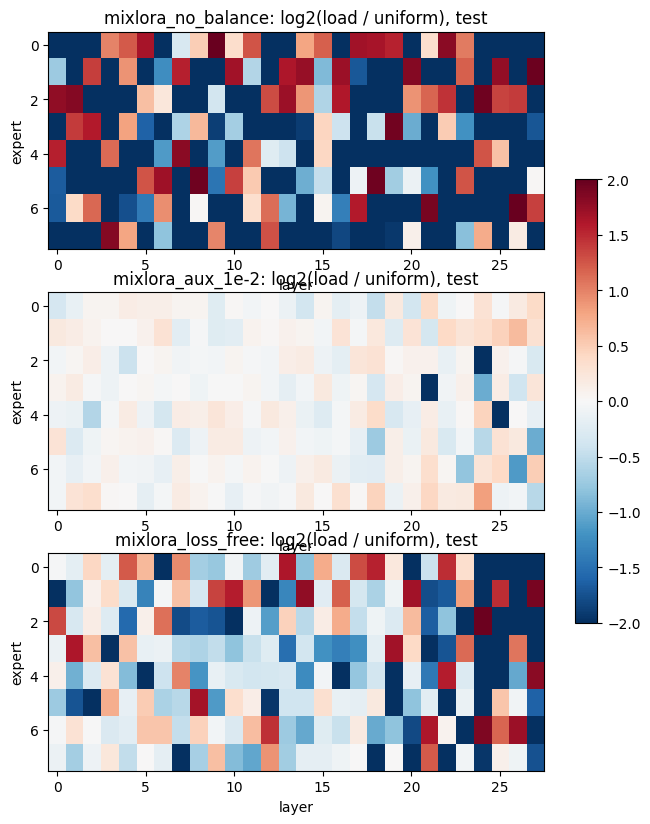

In [19]:
mix_runs = [n for n in RESULTS if RESULTS[n]["spec"]["kind"] == "mixlora"]
fig, axes = plt.subplots(len(mix_runs), 1, figsize=(8, 3.2 * len(mix_runs)))
for ax, name in zip(np.atleast_1d(axes), mix_runs):
    c = torch.tensor(RESULTS[name]["test_counts"])
    rel = (c / c.sum(-1, keepdim=True) * E).clamp_min(1e-3).log2().numpy()
    im = ax.imshow(rel.T, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)
    ax.set_title(f"{name}: log2(load / uniform), test")
    ax.set_xlabel("layer")
    ax.set_ylabel("expert")
fig.colorbar(im, ax=axes, shrink=0.6)
plt.savefig(f"{WORK}/part3_heatmaps.png", dpi=120, bbox_inches="tight")
plt.show()

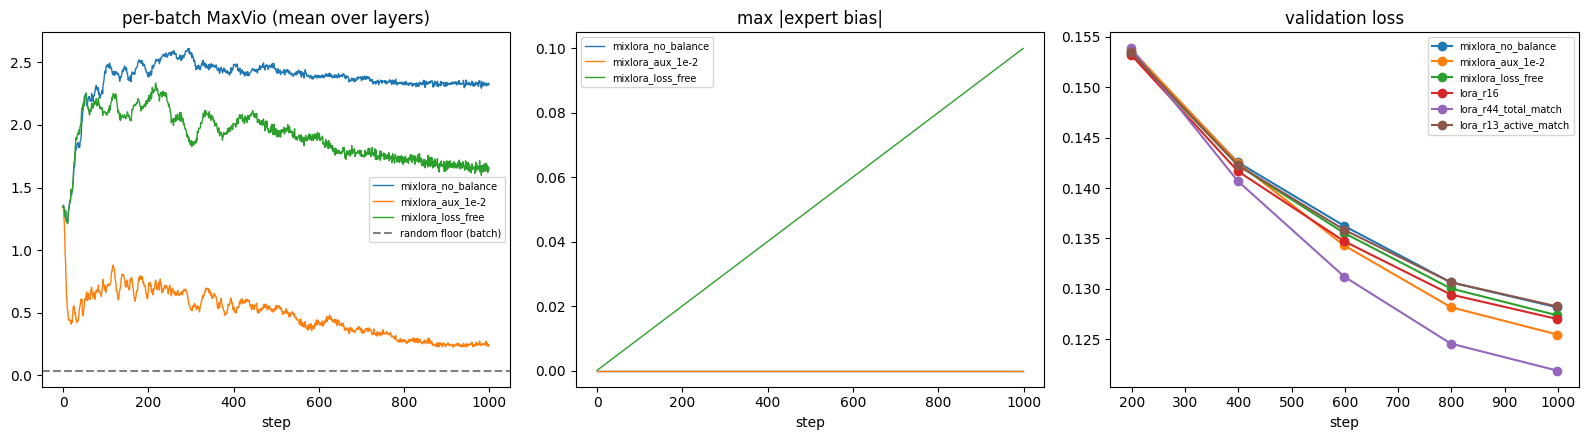

In [20]:
step_batch = CFG3["micro_bs"] * CFG3["grad_accum"]
batch_tokens = int(np.mean([sum(len(e["input_ids"]) for e in TOK3["train"][i:i + step_batch])
                            for i in range(0, 2000, step_batch)]))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name in mix_runs:
    h = RESULTS[name]["history"]
    axes[0].plot(h["step"], h["batch_maxvio_mean"], lw=1, label=name)
    axes[1].plot(h["step"], h["bias_absmax"], lw=1, label=name)
for name, r in RESULTS.items():
    axes[2].plot([v["step"] for v in r["history"]["val"]], [v["loss"] for v in r["history"]["val"]], marker="o", label=name)
axes[0].axhline(random_router_floor(batch_tokens)["maxvio_mean"], color="grey", ls="--", label="random floor (batch)")
axes[0].set_title("per-batch MaxVio (mean over layers)")
axes[1].set_title("max |expert bias|")
axes[2].set_title("validation loss")
for ax in axes:
    ax.set_xlabel("step")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(f"{WORK}/part3_curves.png", dpi=150)
plt.show()

### Prediction-error table

In [21]:
with open(pred_path) as f:
    pred = json.load(f)
print("predictions registered at:", pred["timestamp"])
rows = []
for name, p in pred["predictions"].items():
    if name not in RESULTS:
        continue
    r = RESULTS[name]
    measured = dict(gleu=r["test_metrics"]["gleu"], val_loss=r["history"]["val"][-1]["loss"],
                    maxvio=r.get("test_routing", {}).get("maxvio_mean"))
    for metric, val in measured.items():
        if p.get(metric) is None or val is None:
            continue
        rows.append(dict(run=name, metric=metric, predicted=p[metric], measured=val, error=val - p[metric]))
pred_err = pd.DataFrame(rows)
if len(pred_err):
    display(pred_err.style.format({"predicted": "{:.4f}", "measured": "{:.4f}", "error": "{:+.4f}"}))
    pred_err.to_csv(f"{WORK}/part3_prediction_errors.csv", index=False)
else:
    print("no predictions filled in")

predictions registered at: 2026-10-11 15:22:23
no predictions filled in


### Example corrections

In [22]:
for name in ["zero-shot base"] + list(RESULTS):
    e = (REFERENCE["zero-shot examples"] if name == "zero-shot base" else RESULTS[name]["examples"])[0]
    print(f"--- {name}\nSRC: {e['src'][:300]}\nHYP: {e['hyp'][:300]}\nREF: {e['ref'][:300]}")

--- zero-shot base
SRC: 😡Окупанти готують провокацію на Запорізькій АЕС – можуть влаштувати теракт 19 серпня Головне управління розвідки повідомляє, що росіяни оголосили несподіваний вихідний на ЗАЕС. 19 серпня на станції буде тільки оперативний персонал. Водночас у Міноборони РФ заявили, мовляв, ЗСУ готує теракт на станці
HYP: Текст з виправленнями:

😡 Окупанти готують провокацію на Запорізькій АЕС – можуть влаштувати теракт 19 серпня. Головне управління розвідки повідомляє, що російські особи оголосили несподіваний вихідний на ЗАЕС. 19 серпня на станції буде тільки оперативний персонал. Водночас у Міноборони РФ заявили, 
REF: 😡 Окупанти готують провокацію на Запорізькій АЕС – можуть влаштувати теракт 19 серпня. Головне управління розвідки повідомляє, що росіяни оголосили несподіваний вихідний на ЗАЕС. 19 серпня на станції буде лише оперативний персонал. Водночас у Міноборони РФ заявили, що ЗСУ нібито готує теракт на стан
--- mixlora_no_balance
SRC: 😡Окупанти готують провокацію на Зап